# **Импорт библиотек, установка рабочей директории**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS

In [ ]:
%matplotlib inline
sns.set()

Чтобы программа "увидела" файл с данными, его нужно положить в ту же папку, где находится сама программа.

Загрузите файл с данными на свой гугл-диск и поместите его в папку с программой.

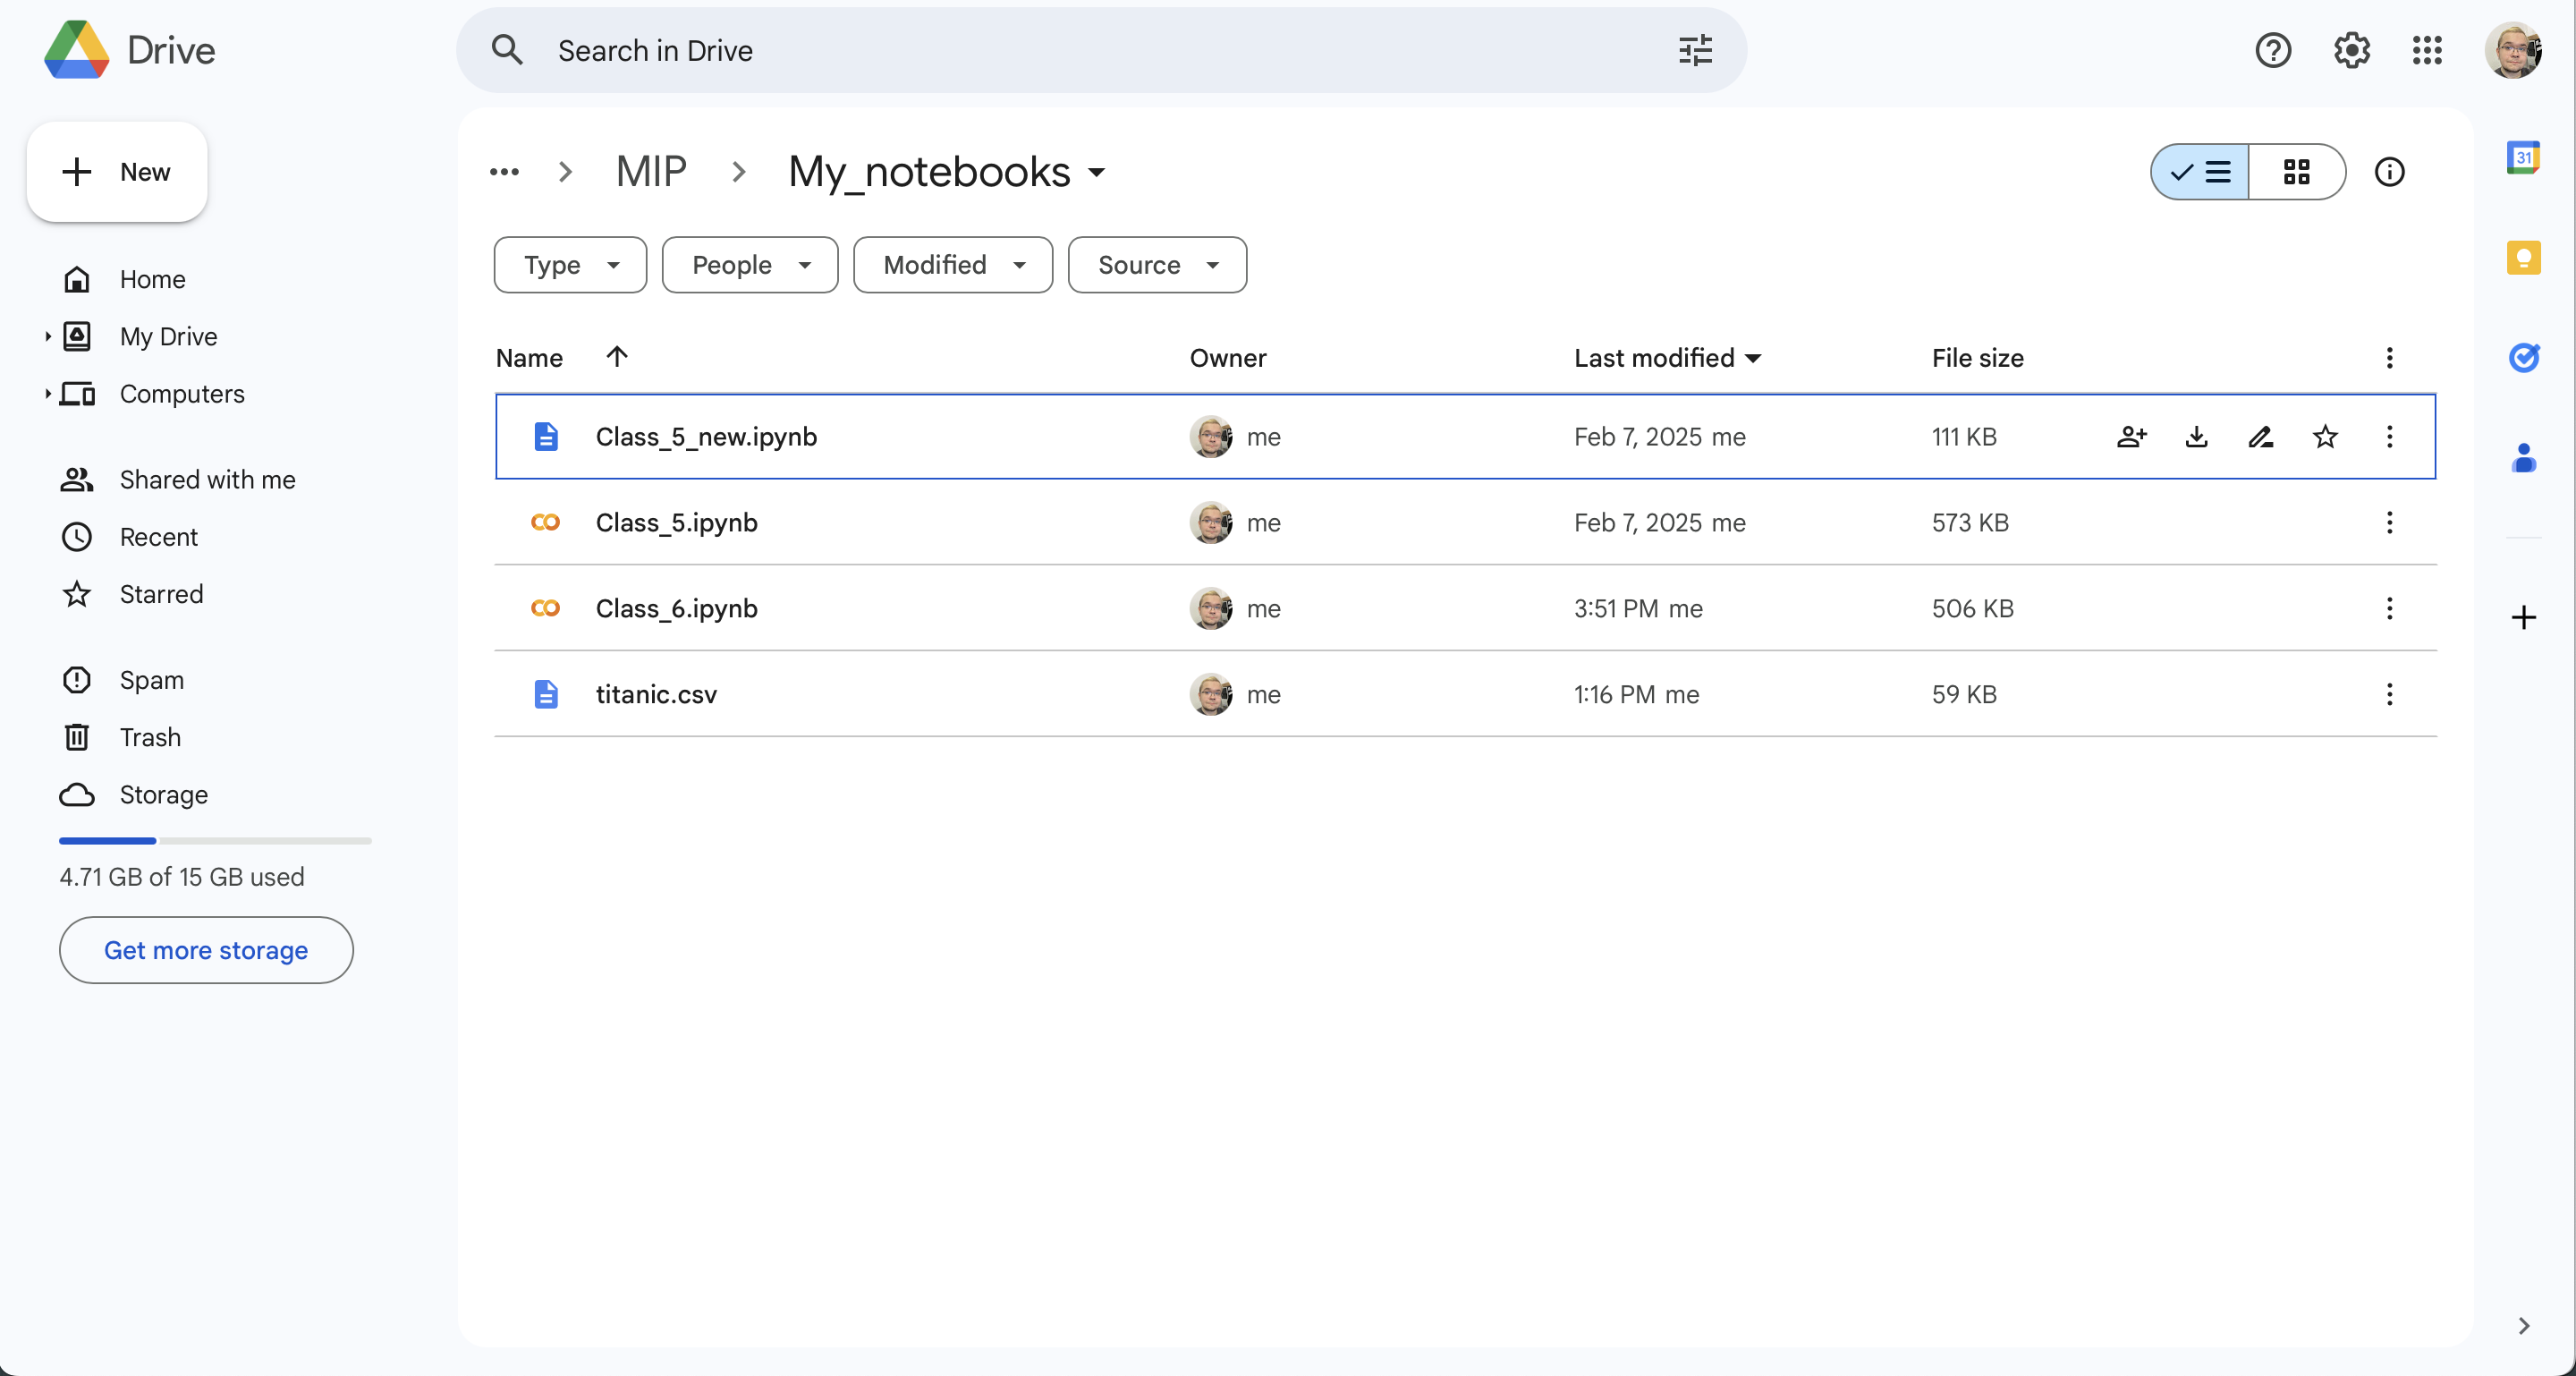


Далее выполните инструкцию:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Наконец, смените текущую рабочую директорию.

В левом меню файлов найдите папку, где находится ваша программа, нажмите на значок троеточия рядом с именем папки, скопируйте ее путь. Выполните следующую инструкцию:

`%cd скопированный путь`

In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks

/content/drive/MyDrive/Colab Notebooks


Проверьте, что вы установили рабочую директорию в правильной папке:

In [ ]:
!pwd

/content/drive/MyDrive/Colab Notebooks


# **Загрузка датасета**

Исследуйте датасет, включающий в себя данные о заболеваемости диабетом у женщин индейского племени Пима.

https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

## *Задание 1*
Загрузите датасет в программу с помощью функции `pd.read_csv()`, датасет сохраните в переменной `data`. В функцию передайте имя файла с датасетом: diabetes.csv

In [ ]:
# Ваш код
data = pd.read_csv('diabetes.csv')
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=data)

https://docs.google.com/spreadsheets/d/1gpdxYPXiREAgtAFA3auAz1ZU9DpmrGbkoc-7GAXPXf0/edit#gid=0


## *Задание 2*

Примените к датасету метод `.info()`

In [ ]:
#Ваш код
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Опишите датасет:

* Сколько записей и параметров содержится в датасете
* Какие параметры доступны для анализа
* Сколько ненулевых значений параметров 'Outcome', 'Pregnancies', 'DiabetesPedigreeFunction' содержится в датасете, укажите, какие типы данных им соответствуют

Ваш ответ:

Датасет содержит 768 записей и 9 колонок

Доступные параметры: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age, Outcome

ненулевых- Outcome: 768 (тип int64), Pregnancies: 768 (тип int64), DiabetesPedigreeFunction: 768(float 64)

# **Описательная статистика, фильтрация данных**

Исследуйте описательную статистику вашего датасета.

## *Задание 3*
Примените к датасету метод `describe()`

In [ ]:
#Ваш код
data.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Напишите, чему равны:

* Максимальное значение индекса массы тела
* Среднее значение значение уровня глюкозы
* Третий квартиль возраста
* Медиана количества беременностей
* 25-перцентиль уровня инсулина
* Стандартное отклонение кровяного давления

Ваш ответ:

Максимальное значение индекса массы тела: 67.1

Среднее значение уровня глюкозы: 120.89453125

Третий квартиль возраста: 41.0

Медиана количества беременностей: 3.0

25-перцентиль уровня инсулина: 0.0

Стандартное отклонение кровяного давления: 19.355807170644777



In [ ]:
print("Максимальное значение индекса массы тела:", data['BMI'].max())

print("Среднее значение уровня глюкозы:", data['Glucose'].mean())

print("Третий квартиль возраста:", data['Age'].quantile(0.75))

print("Медиана количества беременностей:", data['Pregnancies'].median())

print("25-перцентиль уровня инсулина:", data['Insulin'].quantile(0.25))

print("Стандартное отклонение кровяного давления:", data['BloodPressure'].std())


Максимальное значение индекса массы тела: 67.1
Среднее значение уровня глюкозы: 120.89453125
Третий квартиль возраста: 41.0
Медиана количества беременностей: 3.0
25-перцентиль уровня инсулина: 0.0
Стандартное отклонение кровяного давления: 19.355807170644777


## *Задание 4*

* С помощью метода `median()` найдите и выведите на экран медиану уровня глюкозы и инсулина в крови
* С помощью метода `quantile()` найдите и выведите на экран квартили параметра кровяного давления

In [ ]:
# Ваш код
print('Медиана уровня глюкозы:', data['Glucose'].median())
print('Медиана уровня инсулина:', data['Insulin'].median())
print('Квартили параметра BloodPressure:', *data['BloodPressure'].quantile([0.25, 0.5, 0.75]))

Медиана уровня глюкозы: 117.0
Медиана уровня инсулина: 30.5
Квартили параметра BloodPressure: 62.0 72.0 80.0


## *Задание 5*
Найдите и выведите на экран уникальные значения параметров возраста и Outcome (наличие или отсутствие диабета). Используйте метод `unique()`


In [ ]:
#Введите ваш код в принты
print(data['Age'].unique())
print(data['Outcome'].unique())

[50 31 32 21 33 30 26 29 53 54 34 57 59 51 27 41 43 22 38 60 28 45 35 46
 56 37 48 40 25 24 58 42 44 39 36 23 61 69 62 55 65 47 52 66 49 63 67 72
 81 64 70 68]
[1 0]


С помощью функции `len()` найдите количество соответствующих уникальных значений

In [ ]:
#Введите ваш код в принты
print(len(data['Age'].unique()))
print(len(data['Outcome'].unique()))

52
2


## *Задание 6*
Изучите, как распределено количество респондентов по параметру Outcome.

Для этого к соответствующему столбцу последовательно примените методы `sort_values()` и `value_counts(sort=False)`

In [ ]:
#Введите ваш код в принт
print(*data['Outcome'].sort_values().value_counts(sort=False))

500 268


Сколько всего женщин из выборки болело диабетом?

Ваш ответ: 268

## *Задание 7*
В две отдельные таблицы сохраните данные:

1. О респондентах, чей возраст больше либо равен 35 - переменная data_over_35
2. О респондентах, чей возраст меньше 35 - переменная data_under_35

In [ ]:
# Ваш код
data_over_35 = data[data['Age'] >= 35]
data_under_35 = data[data['Age'] < 35]

Сохраните эти таблицы в отдельные файлы с расширением .csv

Используйте метод `.to_csv('Имя_файла.csv', index=False)`

Имя файла должно соответствовать имени переменной

In [ ]:
#Ваш код
data_over_35.to_csv('data_over_35.csv', index=False)
data_under_35.to_csv('data_under_35.csv', index=False)

В две отдельные таблицы сохраните данные:

1. О респондентах, не болеющих диабетом - переменная data_negative
2. О респондентах, болеющих диабетом - переменная data_positive

In [ ]:
#Ваш код
data_negative = data[data['Outcome'] == 0]
data_positive = data[data['Outcome'] == 1]

Сохраните эти таблицы в отдельные файлы с расширением .csv

Используйте метод `.to_csv('Имя_файла.csv', index=False)`

Имя файла должно соответствовать имени переменной

In [ ]:
# Ваш код
data_negative.to_csv('data_negative.csv', index=False)
data_positive.to_csv('data_positive.csv', index=False)

## *Задание 8*
Сгруппируйте данные по переменной Outcome и сравните средние показатели ИМТ у здоровых людей и людей, страдающих от диабета.

In [ ]:
# Ваш код
grouped_outcome_BMI = data.groupby('Outcome').aggregate({'BMI': 'mean'})
print(grouped_outcome_BMI)

               BMI
Outcome           
0        30.304200
1        35.142537


Напишите чему равны:

* Среднее значение ИМТ у здоровых респондентов = 30.304200
* Среднее значение ИМТ у респондентов, больных диабетом = 35.142537

# **Визуализация данных**

## *Задание 9*

Постройте гистограмму распределения параметра BloodPressure. При создании диаграммы укажите количество столбцов, равное 9. Задайте название графика и подписи к осям X и Y



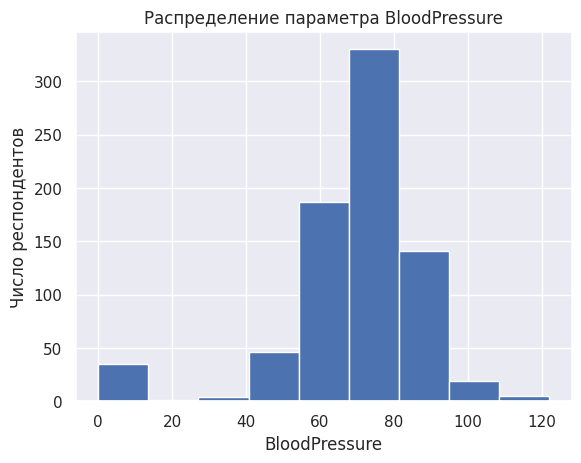

In [ ]:
# Ваш код
# Метод dropna() позволяет игнорировать пустые значения в таблице данных.
pressure_hist = data['BloodPressure'].dropna().hist(bins=9)

# Задаем заголовок графика
plt.title('Распределение параметра BloodPressure')

# Подписываем оси графика
plt.xlabel('BloodPressure')
plt.ylabel('Число респондентов')

# Корректно выводим график на экран
plt.show()

## *Задание 10*
Постройте боксплоты для параметров Insulin, Age и BloodPressure относительно параметра Outcome (наличие или отсутствие диабета)

Для каждого боксплота задайте название и подписи к осям X и Y

Сохраните все боксплоты на диск в форме png с параметром dpi=400

/tmp/ipython-input-203/2338917775.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  outcome_insulin_box = sns.boxplot(x='Outcome', y='Insulin',


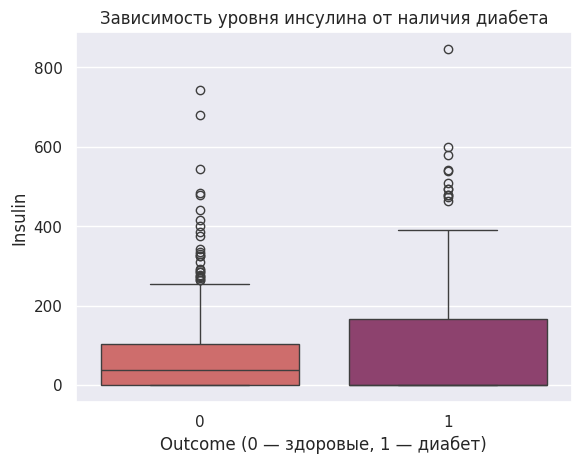

In [ ]:
# Ваш код
# Параметром palette меняем цвет боксплотов
outcome_insulin_box = sns.boxplot(x='Outcome', y='Insulin',
                                  data=data, palette='flare')

plt.title("Зависимость уровня инсулина от наличия диабета")
plt.xlabel("Outcome (0 — здоровые, 1 — диабет)")
plt.ylabel("Insulin")

# Сохраняем график в формате png с dpi=400
plt.savefig("outcome_insulin_box.png", dpi=400)

plt.show()

/tmp/ipython-input-203/4229999591.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  outcome_age_box = sns.boxplot(x='Outcome', y='Age',


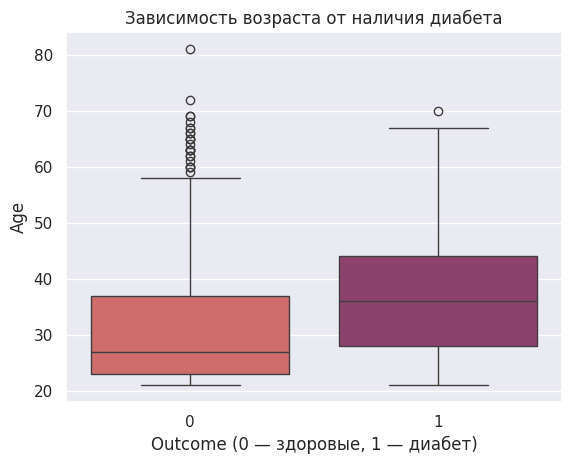

In [ ]:
# Ваш код
# Параметром palette меняем цвет боксплотов
outcome_age_box = sns.boxplot(x='Outcome', y='Age',
                              data=data, palette='flare')

plt.title("Зависимость возраста от наличия диабета")
plt.xlabel("Outcome (0 — здоровые, 1 — диабет)")
plt.ylabel("Age")

# Сохраняем график в формате png с dpi=400
plt.savefig("outcome_age_box.png", dpi=400)

plt.show()

/tmp/ipython-input-203/2693464191.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  outcome_pressure_box = sns.boxplot(x='Outcome', y='BloodPressure',


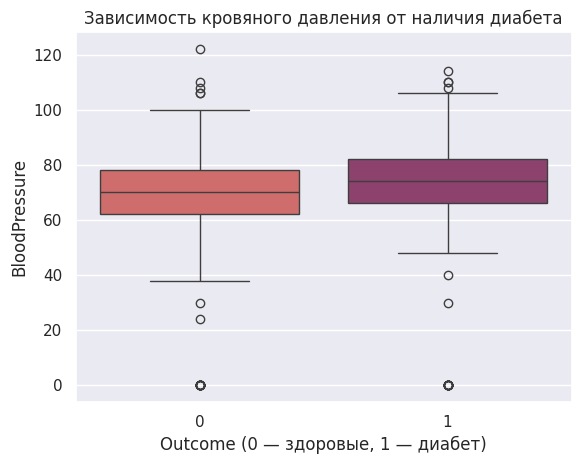

In [ ]:
# Ваш код
# Параметром palette меняем цвет боксплотов
outcome_pressure_box = sns.boxplot(x='Outcome', y='BloodPressure',
                                   data=data, palette='flare')

plt.title("Зависимость кровяного давления от наличия диабета")
plt.xlabel("Outcome (0 — здоровые, 1 — диабет)")
plt.ylabel("BloodPressure")

# Сохраняем график в формате png с dpi=400
plt.savefig("outcome_pressure_box.png", dpi=400)

plt.show()

## *Задание 11*
Постройте гипотезы на основе получившихся графиков

Гипотеза (H0) по первому боксплоту: выборки респондентов с наличием и отсутствием диабета по параметру Insulin статистически не отличаются

Гипотеза (H0) по второму боксплоту: выборки респондентов с наличием и отсутствием диабета по параметру Age статистически не отличаются

Гипотеза (H0) по третьему боксплоту: выборки респондентов с наличием и отсутствием диабета по параметру BloodPressure статистически отличаются

# **Проверка статистических гипотез**

Сравните выборки, полученные вами в задании 7, по различным

Статистически значимые различия обнаружены по параметрам Age и BloodPressure.
По параметру Insulin различий не выявлено


## *Задание 12*

Установите вид распределения (нормальное/не нормальное) полученных вами выборок из задания 7:

* Выборок респондентов старше 35 и выборок респондентов младше 35 по параметрам SkinThickness, Insulin, Pregnancies
* Выборок респондентов с диабетом и выборок респондентов без диабета по параметрам из задания 10

Всего должно быть 12 проверок на нормальность

In [ ]:
# Ваш код
print('выборка респондентов возраст >= 35')
print('p-value критерия шапиро-уилка для параметра skinthickness:',
      stats.shapiro(data_over_35['SkinThickness'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра insulin:',
      stats.shapiro(data_over_35['Insulin'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра pregnancies:',
      stats.shapiro(data_over_35['Pregnancies'].dropna())[1])

print('выборка респондентов возраст < 35')
print('p-value критерия шапиро-уилка для параметра skinthickness:',
      stats.shapiro(data_under_35['SkinThickness'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра insulin:',
      stats.shapiro(data_under_35['Insulin'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра pregnancies:',
      stats.shapiro(data_under_35['Pregnancies'].dropna())[1])

print('выборка респондентов с диабетом (outcome = 1)')
print('p-value критерия шапиро-уилка для параметра insulin:',
      stats.shapiro(data_positive['Insulin'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра age:',
      stats.shapiro(data_positive['Age'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра bloodpressure:',
      stats.shapiro(data_positive['BloodPressure'].dropna())[1])

print('выборка респондентов без диабета (outcome = 0)')
print('p-value критерия шапиро-уилка для параметра insulin:',
      stats.shapiro(data_negative['Insulin'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра age:',
      stats.shapiro(data_negative['Age'].dropna())[1])
print('p-value критерия шапиро-уилка для параметра bloodpressure:',
      stats.shapiro(data_negative['BloodPressure'].dropna())[1])

выборка респондентов возраст >= 35
p-value критерия шапиро-уилка для параметра skinthickness: 3.1190241418750695e-16
p-value критерия шапиро-уилка для параметра insulin: 1.272391177188969e-23
p-value критерия шапиро-уилка для параметра pregnancies: 0.0002686657763842045
выборка респондентов возраст < 35
p-value критерия шапиро-уилка для параметра skinthickness: 7.981177019508982e-14
p-value критерия шапиро-уилка для параметра insulin: 2.7719725332125996e-26
p-value критерия шапиро-уилка для параметра pregnancies: 2.1463606308820805e-19
выборка респондентов с диабетом (outcome = 1)
p-value критерия шапиро-уилка для параметра insulin: 5.2972001281391383e-20
p-value критерия шапиро-уилка для параметра age: 2.0271468445984407e-07
p-value критерия шапиро-уилка для параметра bloodpressure: 1.6336746556819584e-18
выборка респондентов без диабета (outcome = 0)
p-value критерия шапиро-уилка для параметра insulin: 3.022222615773512e-28
p-value критерия шапиро-уилка для параметра age: 2.670546605

Ваши выводы о распределении выборок по этим параметрам:




Для сравнения выборок (респонденты разного возраста; респонденты с наличием/отсутствием диабета) я буду использовать статистический критерий: непараметрический критерий для несвязанных (независимых) выборок — U-критерий Манна–Уитни

## *Задание 13*

На основе результатов, полученных в задании 12, проведите статистические тесты для ваших выборок

Критерии для несвязанных (независимых) выборок
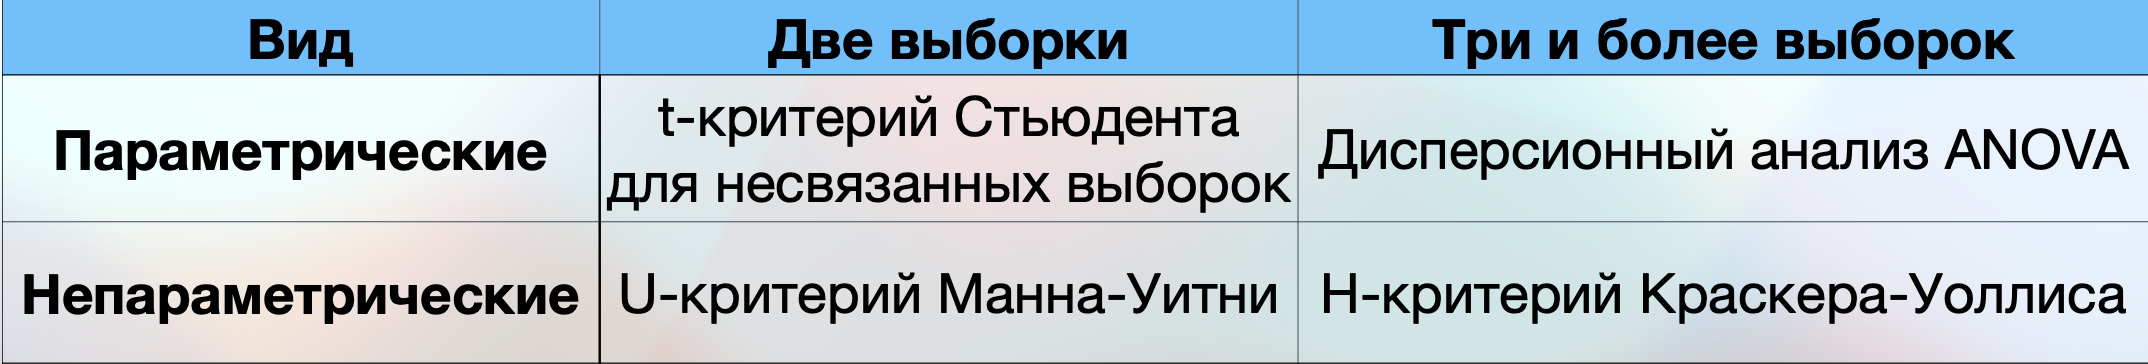

Эти критерии соответствуют следующим функциям в Python:

*   t-критерий Стьюдента для несвязанных выборок - `stats.ttest_ind()`
*   U-критерий Манна-Уитни - `stats.mannwhitneyu()`
* Дисперсионный анализ ANOVA - `stats.f_oneway()`
* H-критерий Краскера-Уоллиса - `stats.kruskal()`



Критерии для связанных (зависимых) выборок
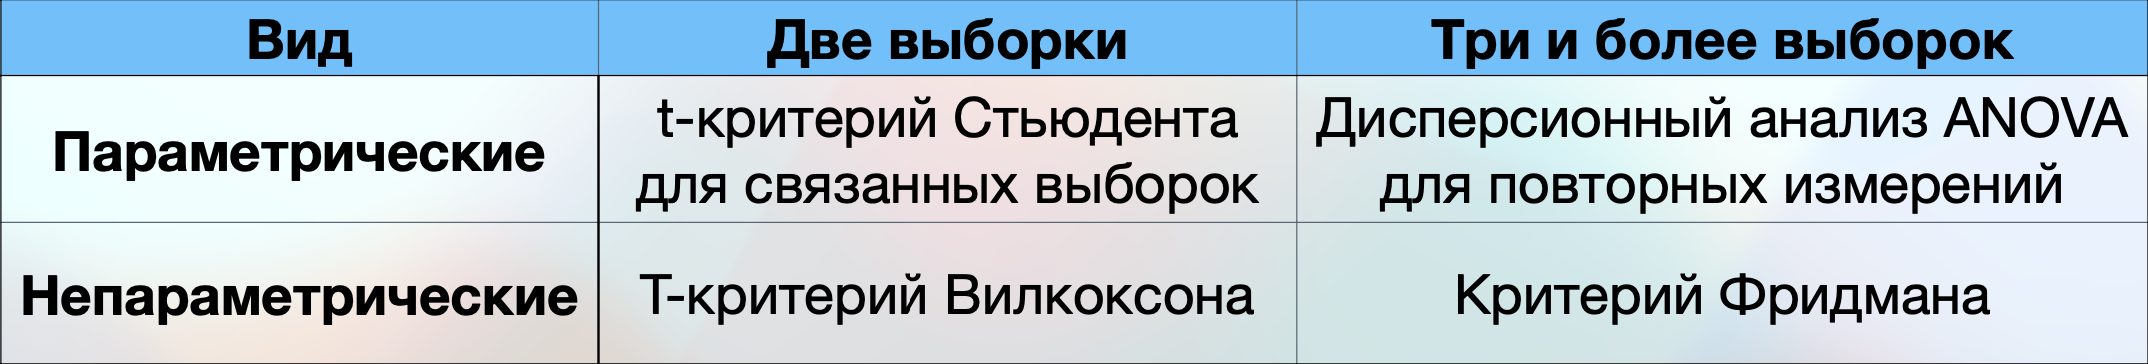

Эти критерии соответствуют следующим функциям в Python:

*   t-критерий Стьюдента для связанных выборок - `stats.ttest_rel()`
*   T-критерий Вилкоксона - `stats.wilcoxon()`
*   Дисперсионный анализ ANOVA для повторных измерений - функция `AnovaRM()` из библиотеки `statsmodels.stats.anova`
*   Критерий Фридмана - `stats.friedmanchisquare()`



Сравните:

1. Выборки респондентов младше 35 и старше 35 по параметрам:
* SkinThickness
* Insulin
* Pregnancies

2. Выборки респондентов с наличием и отсутствием диабета по параметрам:

* Insulin
* Age
* BloodPressure

Всего должно быть проведено 6 статистических тестов

In [ ]:
# Ваш код для выполнения статистических тестов:
print('p-value U-критерия Манна-Уитни при сравнении выборок респондентов младше 35 и старше 35:')
print('По параметру SkinThickness:', stats.mannwhitneyu(data_under_35['SkinThickness'].dropna(), data_over_35['SkinThickness'].dropna())[1])
print('По параметру Insulin:', stats.mannwhitneyu(data_under_35['Insulin'].dropna(), data_over_35['Insulin'].dropna())[1])
print('По параметру Pregnancies:', stats.mannwhitneyu(data_under_35['Pregnancies'].dropna(), data_over_35['Pregnancies'].dropna())[1])
print('p-value U-критерия Манна-Уитни при сравнении выборок респондентов с наличием и отсутствием диабета:')
print('По параметру Insulin:', stats.mannwhitneyu(data_positive['Insulin'].dropna(), data_negative['Insulin'].dropna())[1])
print('По параметру Age:', stats.mannwhitneyu(data_positive['Age'].dropna(), data_negative['Age'].dropna())[1])
print('По параметру BloodPressure:', stats.mannwhitneyu(data_positive['BloodPressure'].dropna(), data_negative['BloodPressure'].dropna())[1])

p-value U-критерия Манна-Уитни при сравнении выборок респондентов младше 35 и старше 35:
По параметру SkinThickness: 0.07295964421641085
По параметру Insulin: 0.00019631922571634243
По параметру Pregnancies: 4.101763099872673e-52
p-value U-критерия Манна-Уитни при сравнении выборок респондентов с наличием и отсутствием диабета:
По параметру Insulin: 0.06566036997824368
По параметру Age: 1.1422001179619007e-17
По параметру BloodPressure: 7.5585124602395e-05


Напишите выводы из проведения статистических тестов. Укажите, подтвердились или опроверглись гипотезы, которые вы выдвинули в задании 11

# **Корреляционный анализ**

## *Задание 14*
Проведите корреляционный анализ для всех пар числовых переменных кроме Outcome для выборки респондентов c диабетом `data_positive`

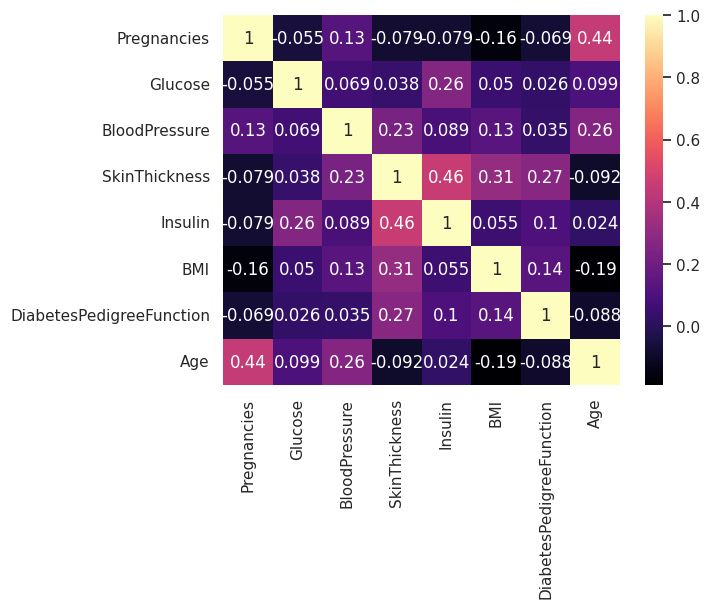

In [ ]:
#Ваш код для проведения корреляционного анализа
corr_positive = data_positive.drop(columns=['Outcome']).corr()
sns.heatmap(corr_positive, annot=True, cmap='magma')
plt.show()

Укажите:

* Параметры, которые положительно коррелируют с Insulin и Age
* Параметры, которые отрицательно коррелируют с DiabetesPedigreeFunction и Pregnancies
* Все пары параметров со средним уровнем корреляции

In [ ]:
print(corr_positive)
print(corr_positive['Insulin'])
print(corr_positive['Age'])
print(corr_positive['DiabetesPedigreeFunction'])

                          Pregnancies   Glucose  BloodPressure  SkinThickness  \
Pregnancies                  1.000000 -0.054591       0.126963      -0.079165   
Glucose                     -0.054591  1.000000       0.068699       0.037618   
BloodPressure                0.126963  0.068699       1.000000       0.225247   
SkinThickness               -0.079165  0.037618       0.225247       1.000000   
Insulin                     -0.078563  0.261368       0.089367       0.456558   
BMI                         -0.159071  0.050418       0.133951       0.312058   
DiabetesPedigreeFunction    -0.069195  0.026474       0.034522       0.273900   
Age                          0.444987  0.098565       0.262684      -0.092012   

                           Insulin       BMI  DiabetesPedigreeFunction  \
Pregnancies              -0.078563 -0.159071                 -0.069195   
Glucose                   0.261368  0.050418                  0.026474   
BloodPressure             0.089367  0.133951    

Ваш ответ:
Положительно коррелируют с Insulin: Glucose, BloodPressure, SkinThickness, BMI, DiabetesPedigreeFunction, Age. Наиболее выраженная положительная связь наблюдается между Insulin и SkinThickness
Положительно коррелируют с Age: Pregnancies, BloodPressure, Glucose, Insulin
Отрицательно коррелируют с DiabetesPedigreeFunction: Pregnancies, Age
Отрицательно коррелируют с Pregnancies: Glucose, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction
Средний уровень корреляции наблюдается между парами:

SkinThickness и Insulin

Pregnancies и Age

SkinThickness и BMI

# **Регрессионный анализ**

## *Задание 15*

Постройте регрессионную модель для выборки респондентов с диабетом: зависимый параметр - DiabetesPedigreeFunction, независимые - все остальные, кроме Outcome. Подберите наилучший набор параметров, произведите проверку на мультиколлинеарность

In [ ]:
# Ваш код для построения регрессионной модели
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
X = data_positive.drop(columns=['Outcome', 'DiabetesPedigreeFunction'])
Y = data_positive['DiabetesPedigreeFunction']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(data_positive.drop(columns=['Outcome', 'DiabetesPedigreeFunction']), prepend=False)

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

print(vif_data)



                               OLS Regression Results                               
Dep. Variable:     DiabetesPedigreeFunction   R-squared:                       0.083
Model:                                  OLS   Adj. R-squared:                  0.058
Method:                       Least Squares   F-statistic:                     3.342
Date:                      Wed, 25 Feb 2026   Prob (F-statistic):            0.00199
Time:                              19:15:46   Log-Likelihood:                -103.47
No. Observations:                       268   AIC:                             222.9
Df Residuals:                           260   BIC:                             251.7
Df Model:                                 7                                         
Covariance Type:                  nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

In [ ]:
X = data_positive['SkinThickness']
Y = data_positive['DiabetesPedigreeFunction']

X = sm.add_constant(X, prepend=False)

model = OLS(Y, X)
res = model.fit()
print(res.summary())

                               OLS Regression Results                               
Dep. Variable:     DiabetesPedigreeFunction   R-squared:                       0.075
Model:                                  OLS   Adj. R-squared:                  0.072
Method:                       Least Squares   F-statistic:                     21.57
Date:                      Wed, 25 Feb 2026   Prob (F-statistic):           5.36e-06
Time:                              19:15:46   Log-Likelihood:                -104.57
No. Observations:                       268   AIC:                             213.1
Df Residuals:                           266   BIC:                             220.3
Df Model:                                 1                                         
Covariance Type:                  nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

## *Задание 16*

Напишите:

* Коэффициент детерминации получившейся регрессионной модели
* Каким образом (положительно/отрицательно) зависимый параметр зависит от получившейся регрессионной модели
* Итоговое уравнение получившейся регрессионной модели



Ваш ответ:


Коэффициент детерминации получившейся регрессионной модели равен 0.075

Зависимый параметр положительно зависит от SkinThickness

Итоговое уравнение получившейся регрессионной модели: DiabetesPedigreeFunction = 0.4226 + 0.0058 * SkinThickness
